<a href="https://colab.research.google.com/github/fadeeva/nakedML/blob/master/MLnotes/005_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05/<br>Linear Regression

In [4]:
import numpy as np
import pandas as pd
import scipy as sp

from sklearn.linear_model import LinearRegression, Lasso, Ridge

import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use('ggplot')
np.random.seed(42)

## Quality Metrics

**MAE** - Mean Absolute Error
$$
MAE = \frac{1}{n}\sum^n_{i=1}{|y_i - y'_i|}
$$

**MAPE** - Mean Absolute Percentage Error
$$
MAPE = \frac{1}{n}\sum^n_{i=1}{\frac{|y_i - y'_i|}{|y_i|}} \cdot 100\%
$$

In [2]:
mae = lambda Y, Yp: 1/len(Y) * np.sum(np.abs(Y - Yp))
mape = lambda Y, Yp: 1/len(Y) * np.sum(np.abs(Y - Yp) / np.abs(Y)) * 100

## Defenition

A regression model is called linear if the predicted value of the target feature Y is computed as a sum of the known features $x_1, x_2, x_3, ... , x_n$ taken with certain weights. The goal is to determine the weights.

$$
y' = w_1x_1 + w_2x_2 + ... + w_mx_m + w_0
$$


>**Note**<br>
>A regression model does NOT have to fit the training data exactly.

<br>

**Weight estimation principle.** The objective is to minimize the deviation between the predicted values and the true values of Y.

>**Note**<br>
>Linear regression is sensitive to outliers — they should be removed beforehand.

$$
|y' - y| = |w_1x_1 + w_0 - y|
$$

$|y' - y|$ — exactly what we need to minimize.

or same:

$$
L(w_1, w_0) = |w_1x_1 + w_0 - y_1| + |w_2x_2 + w_0 - y_2| + |w_3x_3 + w_0 - y_3| + |w_4x_4 + w_0 - y_4|
$$

<br>

Since the absolute value function is not differentiable, the sum of squared deviations is minimized instead:

$$
L(w_1, w_0) = (w_1x_1 + w_0 - y_1)^2 + (w_2x_2 + w_0 - y_2)^2 + (w_3x_3 + w_0 - y_3)^2 + (w_4x_4 + w_0 - y_4)^2
$$

<br>

Next, we compute the partial derivatives and set them equal to zero and calculate values of $w_1$ and $w_0$:

$$
\begin{cases}
\frac{\partial L}{\partial w_1} = 0 \\ \frac{\partial L}{\partial w_0} = 0
\end{cases}
$$

<br>

### Sample

|   | x | y |
|---|---|---|
| A |-1 | 1 |
| B | 0 | 0 |
| C | 1 | 1 |
| D | 2 | 4 |

$$
L(w_1, w_0) = (w_1\cdot(-1) + w_0 - 1)^2 + (w_2\cdot0 + w_0 - 0)^2 + (w_3\cdot1 + w_0 - 1)^2 + (w_4\cdot2 + w_0 - 4)^2
$$

$$
L(w_1, w_0) = 6w_1^2 + 4w_0^2 + 4w_1w_0 - 16w_1 - 12w_0 + 18
$$

$$
\begin{cases}
\frac{\partial L}{\partial w_1} = 12w_1 + 4w_0 - 16 = 0 \\ \frac{\partial L}{\partial w_0} = 4w_1 + 8w_0 - 12 = 0
\end{cases}
$$

$$
w_1 = 1, w_0 = 1, y' = x + 1
$$

<br>

>**Problems**  when constructing systems of linear equations:
> 1. No solution
> 2. More than one solution
> 3. Points 1 and 2 arise when the determinant of the equations equals 0. However, a determinant close to 0 is also problematic.

*These problems arise when there is a linear dependency or strong correlation (multicollinearity) between the non-target features.*

>**Solutions** what we need for good regression model:
> 1. Feature selection. Remove non-target features that are linearly dependent on each other.
> 2. Regression coefficients can be minimized via *regularization*.


In [ ]:
N = 100
noise = 5.0

X = np.random.uniform(0, 10, size=N)

w_true = 2.5   # slope
b_true = 1.0   # intercept

y = w_true * X + b_true + np.random.normal(0, noise, size=N)

X_2d = X.reshape(-1, 1)

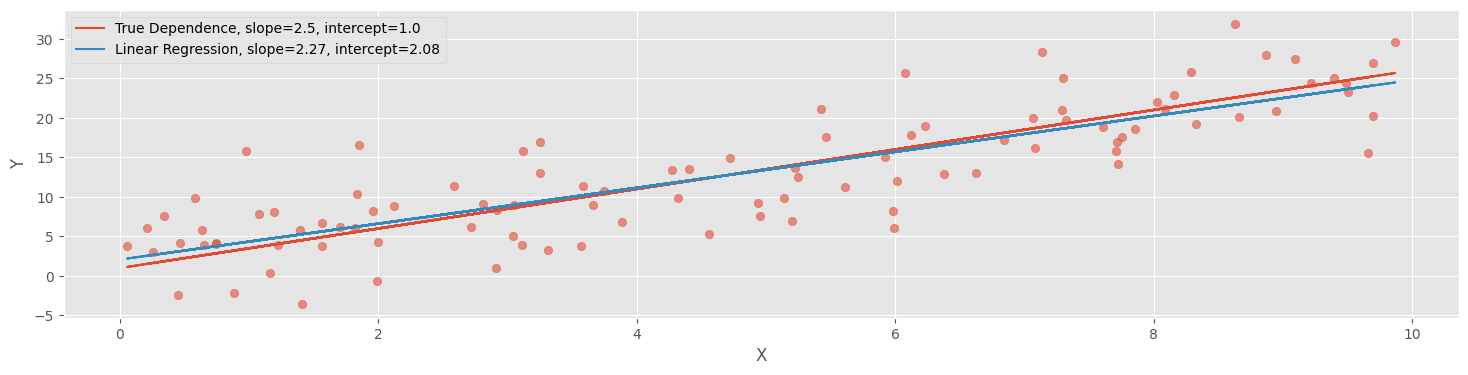

In [3]:
model = LinearRegression()
model.fit(X_2d, y)

w_lr = model.coef_[0]
b_lr = model.intercept_

plt.figure(figsize=(18, 4))
plt.scatter(X, y, alpha=0.6)
plt.plot(X, w_true * X + b_true, label=f'True Dependence, slope={w_true}, intercept={b_true}')
plt.plot(X, w_lr * X + b_lr, label=f'Linear Regression, slope={w_lr:.2f}, intercept={b_lr:.2f}')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()

## Regularization

Main idea:

$$
R = L(w_1, w_2, ..., w_m, w_0) + C(w_1^2 + w_2^2 + ... + w_m^2 + w_0^2)
$$
where $C$ is a given constant.


### Sample

let $C = 1$ =>
$$R = L(w_1, w_2, ..., w_m, w_0) + w_1^2 + w_2^2 + ... + w_m^2 + w_0^2$$

|   | $x_1$ | $x_2$ | Y |
|---|-------|-------|---|
| A |-1     | -1    | 1 |
| B | 0     | 0     | 0 |
| C | 1     | 1     | 1 |
| D | 2     | 2     | 4 |

$$
\begin{cases}
\frac{\partial R}{\partial w_1} = (12w_1 + 12w_2 + 4w_0 - 16) + 2w_1 = 16, w_1 = 1.36
\\
\frac{\partial R}{\partial w_2} = (12w_1 + 12w_2 + 4w_0 - 16) + 2w_2 = 16, w_2 = -0.25
\\
\frac{\partial R}{\partial w_0} = (4w_1 + 4w_2 + 8w_0 - 12) + 2w_0 = 12, w_0 = 0.75
\end{cases}
$$


>**How to choose $C$:**
> 1. Choose as many different values of C as possible.
> 2. For each value, train a regression model and evaluate its performance on the test set.
> 3. Select the value of C that belongs to the model with the best performance.


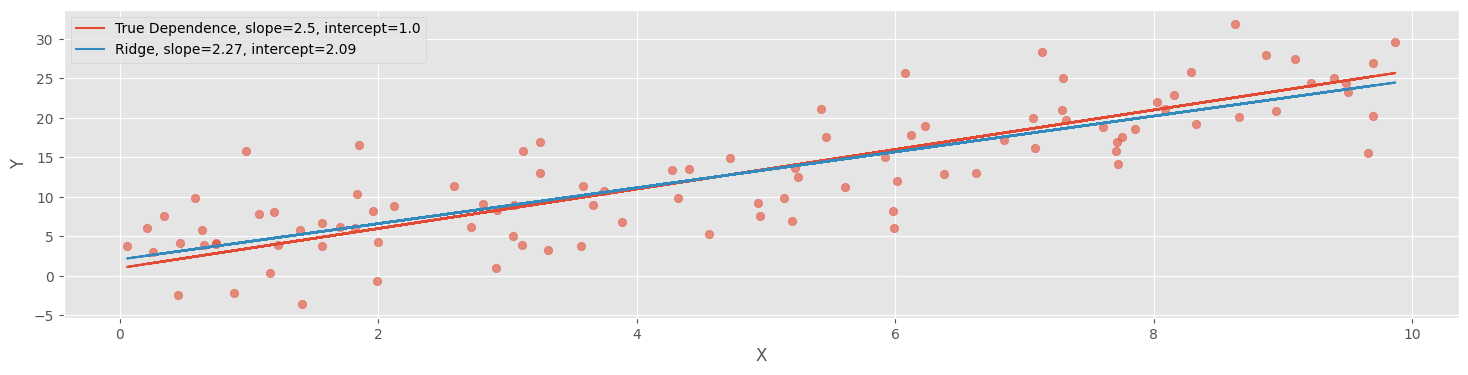

In [9]:
model = Ridge()
model.fit(X_2d, y)

w_rd = model.coef_[0]
b_rd = model.intercept_

plt.figure(figsize=(18, 4))
plt.scatter(X, y, alpha=0.6)
plt.plot(X, w_true * X + b_true, label=f'True Dependence, slope={w_true}, intercept={b_true}')
plt.plot(X, w_rd * X + b_rd, label=f'Ridge, slope={w_rd:.2f}, intercept={b_rd:.2f}')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()

### Lasso

$$
R = L(w_1, w_2, ..., w_m, w_0) + C(|w_1| + |w_2| + ... + |w_m| + |w_0|)
$$

Here, $w$ can only be found using optimization methods.

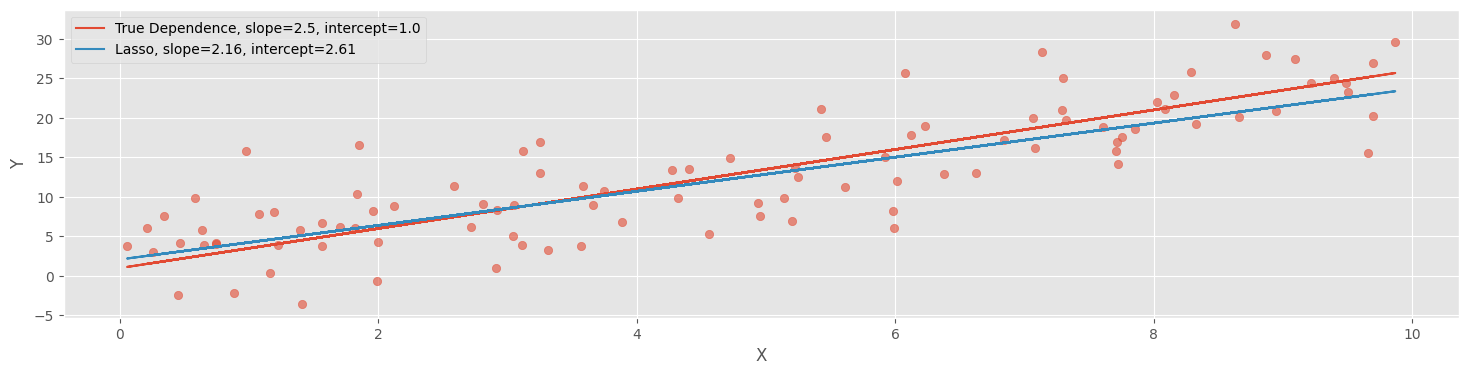

In [8]:
model = Lasso()
model.fit(X_2d, y)

w_ls = model.coef_[0]
b_ls = model.intercept_

plt.figure(figsize=(18, 4))
plt.scatter(X, y, alpha=0.6)
plt.plot(X, w_true * X + b_true, label=f'True Dependence, slope={w_true}, intercept={b_true}')
plt.plot(X, w_ls * X + b_rd, label=f'Lasso, slope={w_ls:.2f}, intercept={b_ls:.2f}')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()

## Polynomial regression

In general, if one wants to find the dependence of the target feature in the form of a polynomial of degree k, new columns must be added to the table containing all possible products of non-target variables of degree at most k.

|   | $x$ | $z$ |$xx$| $zz$ | $xz$ | Y |
|---|-----|-----|----|------|------|---|
| A | 1   |  3  | 1  |   9  |  3   |100|
| B | 1   |  4  | 4  |  16  |  8   |200|

> **Note**<br>
> Increasing the degree of the polynomial does not necessarily improve prediction accuracy.